# 02 — Stability
Goal: for every cell and every "day revealed" (1–21), compute the running estimate,
its uncertainty, and a stability state for the map.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 25)
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
PROCESSED = Path("..") / "data" / "processed"

daily = pd.read_parquet(PROCESSED / "daily_evening.parquet")
cells = pd.read_csv(PROCESSED / "cells.csv", index_col="GEOHASH")

daily = daily[sorted(daily.columns)]
DAYS = list(daily.columns)
D = len(DAYS)

print("daily:", daily.shape, "| cells:", cells.shape)
print("First day:", DAYS[0], "| last day:", DAYS[-1], "| number of days:", D)

daily: (2406, 21) | cells: (2406, 6)
First day: 2024-10-01 | last day: 2024-10-31 | number of days: 21


In [3]:
print("Same cells in the same order:", (daily.index == cells.index).all())

recomputed = daily.mean(axis=1)
print("Max difference in final mean:", (recomputed - cells["final_mean"]).abs().max())

print("Cells for analysis:", cells["enough_days"].sum(), "| no data:", (~cells["enough_days"]).sum())

Same cells in the same order: True
Max difference in final mean: 1.4210854715202004e-14
Cells for analysis: 2363 | no data: 43


## Step 2 — Progressive estimates
For each cell and each number of revealed days t: n, running mean, running std, 95% half-width.

In [4]:
by_day = daily.T

n_t = by_day.expanding().count().T
mean_t = by_day.expanding().mean().T
std_t = by_day.expanding().std().T

for table in (n_t, mean_t, std_t):
    table.columns = range(1, D + 1)

print(n_t.shape)
mean_t.loc[["sxk9n7", "sxk3bt", "sxk9x2"], [1, 2, 3, 5, 10, 21]].round(1)


(2406, 21)


,1,2,3,5,10,21
GEOHASH,,,,,,
sxk9n7,18.7,19.0,19.4,20.0,20.0,20.1
sxk3bt,100.3,100.2,99.9,98.5,97.7,96.8
sxk9x2,94.3,95.7,91.6,96.5,99.8,98.2


In [5]:
dof = (n_t - 1).clip(lower=1)
t_crit = pd.DataFrame(stats.t.ppf(0.975, dof), index=n_t.index, columns=n_t.columns)

half_t = t_crit * std_t / np.sqrt(n_t)

half_t.loc[["sxk9n7", "sxk3bt", "sxk9x2"], [2, 3, 5, 10, 21]].round(2)

,2,3,5,10,21
GEOHASH,,,,,
sxk9n7,4.24,2.08,1.21,0.73,0.38
sxk3bt,2.12,1.26,2.35,1.48,0.94
sxk9x2,16.94,18.00,10.51,4.90,3.71


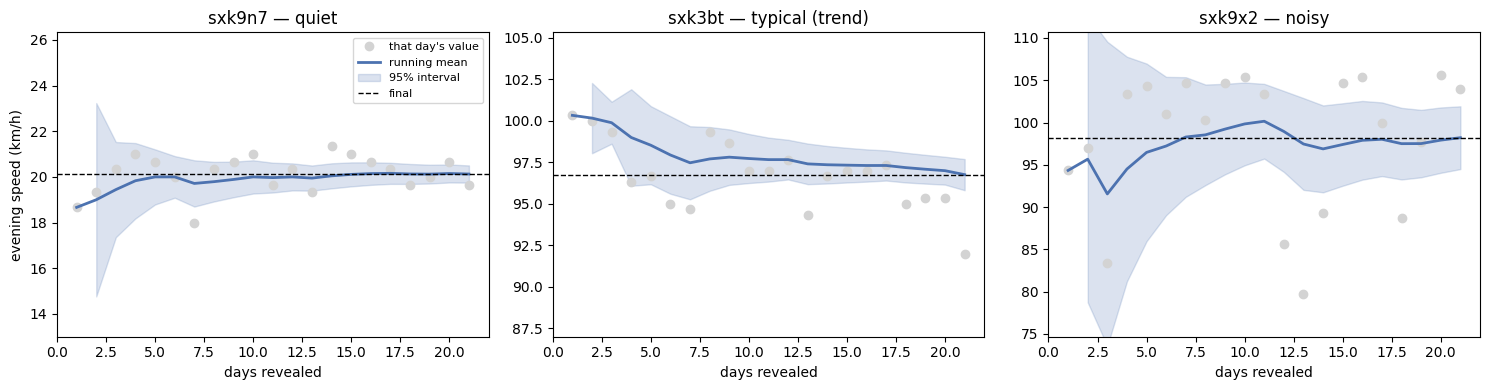

In [6]:
examples = {"sxk9n7": "quiet", "sxk3bt": "typical (trend)", "sxk9x2": "noisy"}
x = np.arange(1, D + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (cell, label) in zip(axes, examples.items()):
    m, h = mean_t.loc[cell], half_t.loc[cell]
    ax.plot(x, daily.loc[cell].values, "o", color="lightgrey", label="that day's value")
    ax.plot(x, m, color="#4C72B0", lw=2, label="running mean")
    ax.fill_between(x, m - h, m + h, color="#4C72B0", alpha=0.2, label="95% interval")
    ax.axhline(m[D], color="black", ls="--", lw=1, label="final")
    ax.set_ylim(daily.loc[cell].min() - 5, daily.loc[cell].max() + 5)
    ax.set_title(f"{cell} — {label}")
    ax.set_xlabel("days revealed")
axes[0].set_ylabel("evening speed (km/h)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

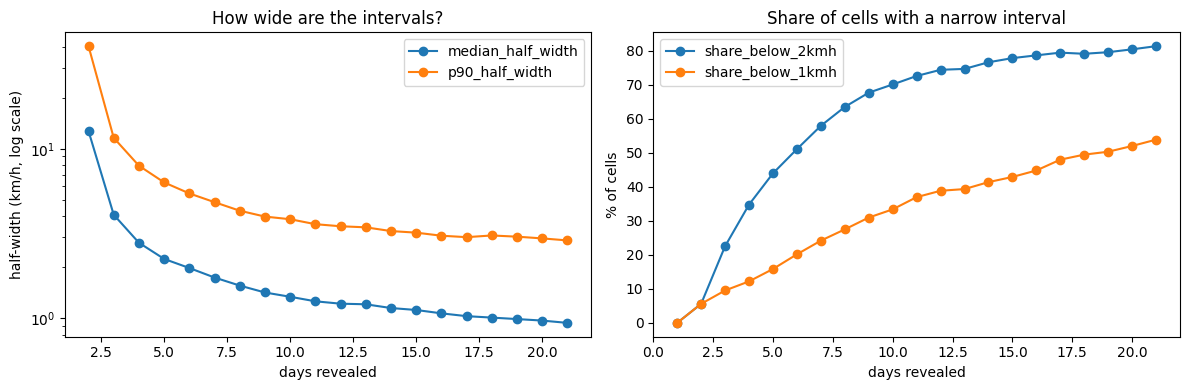

,median_half_width,p90_half_width,share_below_2kmh,share_below_1kmh
2,12.71,40.24,5.59,5.59
3,4.08,11.59,22.51,9.52
5,2.24,6.33,43.93,15.83
7,1.74,4.84,57.89,24.16
10,1.34,3.84,70.04,33.35
15,1.12,3.20,77.78,42.87
21,0.94,2.88,81.29,53.83


In [7]:
analysis = cells["enough_days"]
h = half_t[analysis]

summary = pd.DataFrame({
    "median_half_width": h.median(),
    "p90_half_width": h.quantile(0.9),
    "share_below_2kmh": (h < 2).mean() * 100,
    "share_below_1kmh": (h < 1).mean() * 100,
}).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary[["median_half_width", "p90_half_width"]].plot(ax=axes[0], marker="o", logy=True)
axes[0].set_xlabel("days revealed"); axes[0].set_ylabel("half-width (km/h, log scale)")
axes[0].set_title("How wide are the intervals?")

summary[["share_below_2kmh", "share_below_1kmh"]].plot(ax=axes[1], marker="o")
axes[1].set_xlabel("days revealed"); axes[1].set_ylabel("% of cells")
axes[1].set_title("Share of cells with a narrow interval")
plt.tight_layout()
plt.show()

summary.loc[[2, 3, 5, 7, 10, 15, 21]]

## Step 3 — Rule A: change-only
A cell is "settled" if its running mean moved less than C km/h over the last K days.
We judge rules by comparing each shown value with the final (all-days) value.

In [8]:
K = 3          # look back this many days
C = 1.0        # "stopped moving" = changed less than this (km/h)
MIN_N = 5      # never call a cell settled with fewer than 5 days of data
TOL = 3.0      # a shown value is "wrong" if it is more than 3 km/h from the final value

analysis = cells["enough_days"]
final = mean_t[D]

In [9]:
change_t = (mean_t - mean_t.shift(K, axis=1)).abs()

settled_A = (change_t < C) & (n_t >= MIN_N)
settled_A = settled_A.where(analysis, False)

error_t = (mean_t - final.values[:, None]).abs()

change_t.loc[["sxk9n7", "sxk3bt", "sxk9x2"], [5, 8, 10, 12, 15]].round(2)

,5,8,10,12,15
GEOHASH,,,,,
sxk9n7,1.00,0.21,0.29,0.11,0.11
sxk3bt,1.63,0.83,0.26,0.15,0.33
sxk9x2,0.80,2.07,1.55,0.28,1.54


In [10]:
def evaluate(settled, name):
    s = settled[analysis]
    e = error_t[analysis]
    wrong = s & (e > TOL)
    return pd.DataFrame({
        f"{name}_settled_%": s.mean() * 100,
        f"{name}_wrong_%_of_settled": wrong.sum() / s.sum().replace(0, np.nan) * 100,
    })

res_A = evaluate(settled_A, "A")
res_A.loc[[5, 7, 10, 12, 14, 17, 21]].round(1)

,A_settled_%,A_wrong_%_of_settled
5,59.2,4.4
7,76.6,3.6
10,89.3,3.1
12,90.9,2.4
14,90.4,1.1
17,95.1,0.1
21,96.1,0.0


In [11]:
T = 10
fails = settled_A[T] & (error_t[T] > TOL) & analysis
print(f"Day {T}: {settled_A[T][analysis].sum()} cells settled, {fails.sum()} of them wrong (> {TOL} km/h)")

worst = error_t.loc[fails, T].sort_values(ascending=False).head(5).index
pd.DataFrame({
    "shown at day 10": mean_t.loc[worst, T],
    "final": final[worst],
    "error": error_t.loc[worst, T],
    "change last 3 days": change_t.loc[worst, T],
    "half-width": half_t.loc[worst, T],
}).round(2)

Day 10: 2110 cells settled, 65 of them wrong (> 3.0 km/h)


,shown at day 10,final,error,change last 3 days,half-width
GEOHASH,,,,,
sxk691,88.90,77.73,11.17,0.67,1.66
sxk4xb,68.57,77.83,9.26,0.04,8.14
sx7fqv,87.23,79.92,7.31,0.47,1.12
sxk68d,93.43,86.21,7.23,0.85,1.74
sx7fw9,82.93,75.90,7.03,0.60,1.21


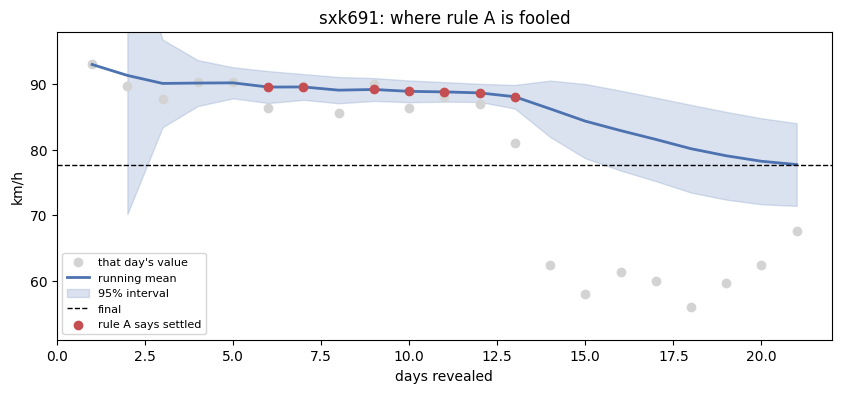

In [12]:
cell = worst[0]
x = np.arange(1, D + 1)
m, h = mean_t.loc[cell], half_t.loc[cell]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, daily.loc[cell].values, "o", color="lightgrey", label="that day's value")
ax.plot(x, m, color="#4C72B0", lw=2, label="running mean")
ax.fill_between(x, m - h, m + h, color="#4C72B0", alpha=0.2, label="95% interval")
ax.axhline(final[cell], color="black", ls="--", lw=1, label="final")

s = settled_A.loc[cell]
ax.scatter(x[s.values], m[s].values, color="#C44E52", zorder=3, label="rule A says settled")
ax.set_ylim(daily.loc[cell].min() - 5, daily.loc[cell].max() + 5)
ax.set_title(f"{cell}: where rule A is fooled")
ax.set_xlabel("days revealed"); ax.set_ylabel("km/h")
ax.legend(fontsize=8)
plt.show()

## Step 4 — Rule B: interval + change
Settled if: change over last K days < C AND half-width < W AND n ≥ MIN_N.
Expected: fixes noisy-but-flat failures; cannot foresee sudden changes.

In [13]:
W = 2.0   # interval must be narrower than ± 2 km/h

settled_B = (change_t < C) & (half_t < W) & (n_t >= MIN_N)
settled_B = settled_B.where(analysis, False)

res_B = evaluate(settled_B, "B")
compare = pd.concat([res_A, res_B], axis=1)
compare.loc[[5, 7, 10, 12, 14, 17, 21]].round(1)

,A_settled_%,A_wrong_%_of_settled,B_settled_%,B_wrong_%_of_settled
5,59.2,4.4,39.1,1.5
7,76.6,3.6,55.6,1.4
10,89.3,3.1,69.4,1.5
12,90.9,2.4,73.6,1.3
14,90.4,1.1,75.8,0.7
17,95.1,0.1,79.1,0.0
21,96.1,0.0,81.1,0.0


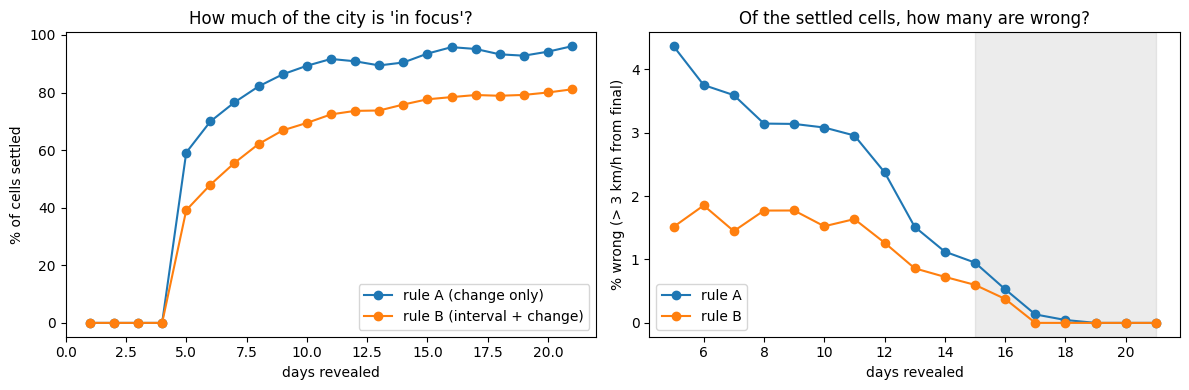

In [14]:
days = compare.index
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(days, compare["A_settled_%"], "o-", label="rule A (change only)")
axes[0].plot(days, compare["B_settled_%"], "o-", label="rule B (interval + change)")
axes[0].set_title("How much of the city is 'in focus'?")
axes[0].set_xlabel("days revealed"); axes[0].set_ylabel("% of cells settled")
axes[0].legend()

axes[1].plot(days, compare["A_wrong_%_of_settled"], "o-", label="rule A")
axes[1].plot(days, compare["B_wrong_%_of_settled"], "o-", label="rule B")
axes[1].axvspan(15, 21, color="grey", alpha=0.15)
axes[1].set_title("Of the settled cells, how many are wrong?")
axes[1].set_xlabel("days revealed"); axes[1].set_ylabel("% wrong (> 3 km/h from final)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../assets/fig_rule_tradeoff.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
T = 10
fails_A = settled_A[T] & (error_t[T] > TOL) & analysis
fails_B = settled_B[T] & (error_t[T] > TOL) & analysis

fixed = fails_A & ~settled_B[T]
print(f"Day {T}: rule A wrong in {fails_A.sum()} cells, rule B wrong in {fails_B.sum()} cells")
print(f"Rule A failures that B refuses to call settled: {fixed.sum()}")

summary_fail = pd.DataFrame({
    "fixed by B": half_t.loc[fixed, T].describe(),
    "still wrong in B": half_t.loc[fails_B, T].describe(),
}).round(2)
summary_fail.loc[["count", "mean", "50%", "max"]]

Day 10: rule A wrong in 65 cells, rule B wrong in 25 cells
Rule A failures that B refuses to call settled: 40


,fixed by B,still wrong in B
count,40.00,25.00
mean,4.20,1.37
50%,3.76,1.41
max,11.58,1.76


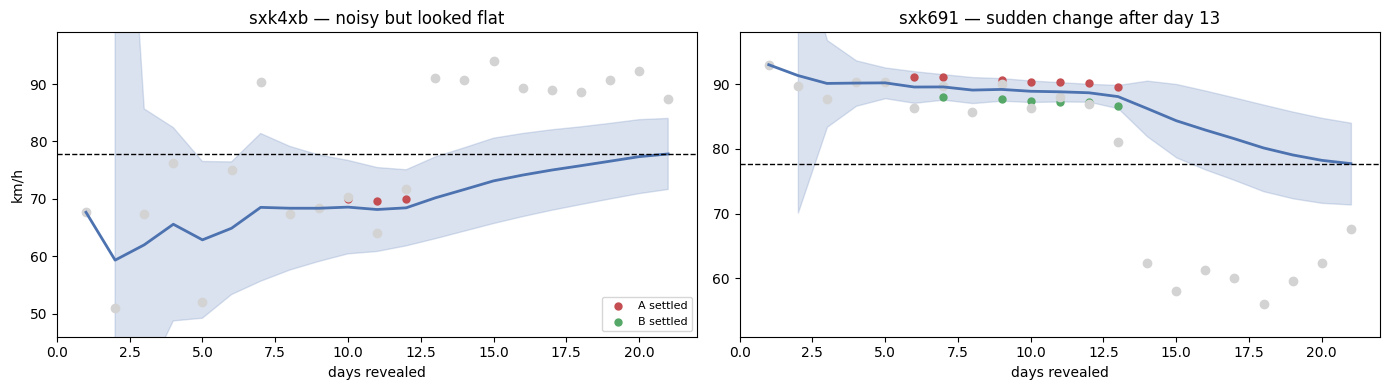

In [16]:
pair = ["sxk4xb", "sxk691"]
titles = ["sxk4xb — noisy but looked flat", "sxk691 — sudden change after day 13"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, cell, title in zip(axes, pair, titles):
    m, h = mean_t.loc[cell], half_t.loc[cell]
    ax.plot(x, daily.loc[cell].values, "o", color="lightgrey")
    ax.plot(x, m, color="#4C72B0", lw=2)
    ax.fill_between(x, m - h, m + h, color="#4C72B0", alpha=0.2)
    ax.axhline(final[cell], color="black", ls="--", lw=1)
    sA, sB = settled_A.loc[cell].values, settled_B.loc[cell].values
    ax.scatter(x[sA], m[sA] + 1.5, color="#C44E52", s=25, label="A settled")
    ax.scatter(x[sB], m[sB] - 1.5, color="#55A868", s=25, label="B settled")
    ax.set_ylim(daily.loc[cell].min() - 5, daily.loc[cell].max() + 5)
    ax.set_title(title); ax.set_xlabel("days revealed")
axes[0].set_ylabel("km/h"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Step 5 — Map states
0 = no data, 1 = forming, 2 = settling, 3 = settled (rule B).
Also flag "lost focus": settled on day t−1 but not on day t.

In [17]:
STATE_NAMES = {0: "no data", 1: "forming", 2: "settling", 3: "settled"}

state = pd.DataFrame(1, index=mean_t.index, columns=mean_t.columns)
state = state.mask(n_t >= MIN_N, 2)
state = state.mask(settled_B, 3)
state.loc[~analysis, :] = 0

state.loc[["sxk9n7", "sxk3bt", "sxk9x2", "sxk691", "sxk4xb"]]

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
GEOHASH,,,,,,,,,,,,,,,,,,,,,
sxk9n7,1,1,1,1,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
sxk3bt,1,1,1,1,2,2,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3
sxk9x2,1,1,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2
sxk691,1,1,1,1,2,2,3,2,3,3,3,3,3,2,2,2,2,2,2,2,2
sxk4xb,1,1,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2


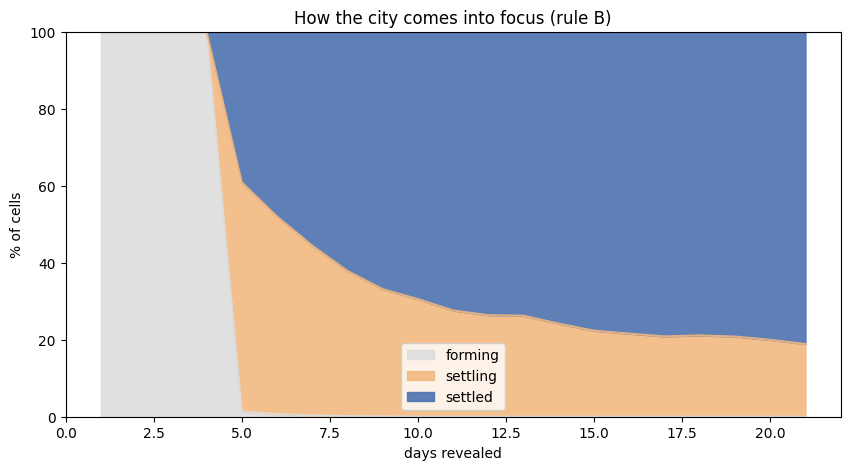

,3,5,10,15,21
forming,100.0,1.4,0.0,0.0,0.0
settling,0.0,59.5,30.6,22.3,18.9
settled,0.0,39.1,69.4,77.7,81.1


In [18]:
counts = state[analysis].apply(lambda col: col.value_counts(normalize=True) * 100).fillna(0)
counts.index = [STATE_NAMES[i] for i in counts.index]

ax = counts.T[["forming", "settling", "settled"]].plot.area(
    color=["#DDDDDD", "#F2B880", "#4C72B0"], alpha=0.9)
ax.set_xlabel("days revealed"); ax.set_ylabel("% of cells")
ax.set_title("How the city comes into focus (rule B)")
ax.set_ylim(0, 100)
plt.savefig("../assets/fig_city_states.png", dpi=200, bbox_inches="tight")
plt.show()

counts.loc[:, [3, 5, 10, 15, 21]].round(1)

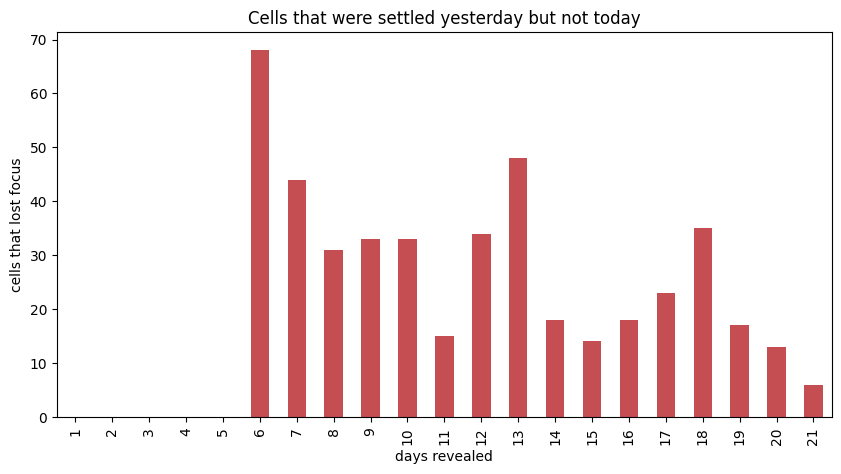

Total 'lost focus' events: 450
Cells that lost focus at least once: 388


In [ ]:
lost = (state.shift(1, axis=1) == 3) & (state < 3)
lost_per_day = lost[analysis].sum()

ax = lost_per_day.plot(kind="bar", color="#C44E52")
ax.set_xlabel("days revealed"); ax.set_ylabel("cells that lost focus")
ax.set_title("Cells that were settled yesterday but not today")
plt.savefig("../assets/fig_lost_focus.png", dpi=200, bbox_inches="tight")
plt.show()

print("Total 'lost focus' events:", lost_per_day.sum())
print("Cells that lost focus at least once:", lost[analysis].any(axis=1).sum())

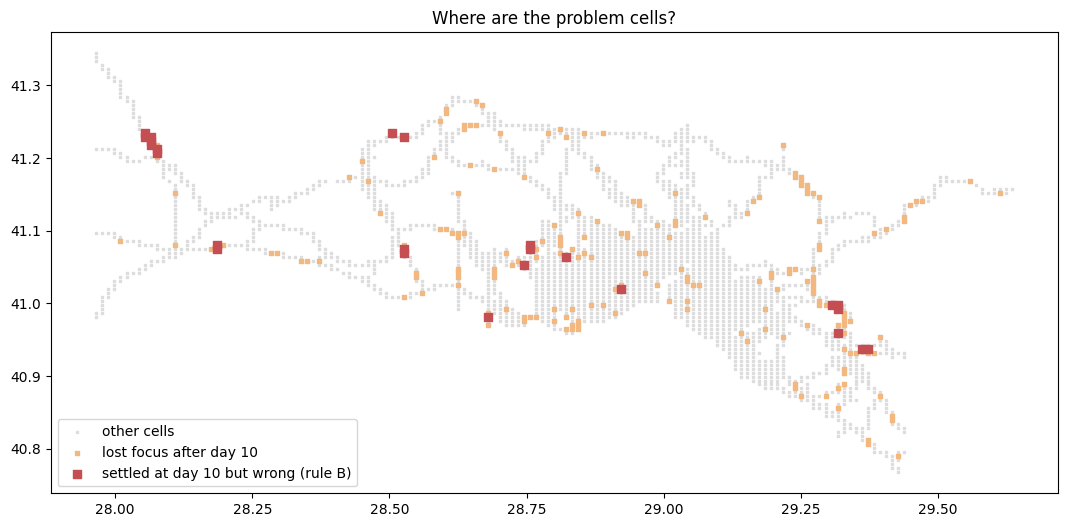

Wrong at day 10 (B): 25 | lost focus after day 10: 221


In [21]:
T = 10
wrong_B = settled_B[T] & (error_t[T] > TOL) & analysis
lost_later = lost.loc[:, 11:21].any(axis=1) & analysis

fig, ax = plt.subplots(figsize=(13, 6))
ok = analysis & ~wrong_B & ~lost_later
ax.scatter(cells.loc[ok, "lon"], cells.loc[ok, "lat"], s=4, color="#DDDDDD", marker="s", label="other cells")
ax.scatter(cells.loc[lost_later, "lon"], cells.loc[lost_later, "lat"], s=12, color="#F2B880", marker="s",
           label="lost focus after day 10")
ax.scatter(cells.loc[wrong_B, "lon"], cells.loc[wrong_B, "lat"], s=30, color="#C44E52", marker="s",
           label="settled at day 10 but wrong (rule B)")
ax.set_aspect(1 / np.cos(np.radians(41)))
ax.set_title("Where are the problem cells?")
ax.legend(loc="lower left")
plt.show()

print("Wrong at day 10 (B):", wrong_B.sum(), "| lost focus after day 10:", lost_later.sum())

In [22]:
progress = pd.DataFrame({
    "geohash": np.repeat(mean_t.index.values, D),
    "t": np.tile(np.arange(1, D + 1), len(mean_t)),
    "mean": mean_t.values.ravel(),
    "half": half_t.values.ravel(),
    "n": n_t.values.ravel(),
    "state": state.values.ravel(),
    "settled_A": settled_A.values.ravel(),
})

progress.to_parquet(PROCESSED / "progress.parquet", index=False)
print(progress.shape)
progress.head(8)

(50526, 7)


,geohash,t,mean,half,n,state,settled_A
0,sx7chk,1,88.666667,NaN,1.0,1,False
1,sx7chk,2,89.000000,4.235402,2.0,1,False
2,sx7chk,3,88.222222,3.447430,3.0,1,False
3,sx7chk,4,87.416667,3.134197,4.0,1,False
4,sx7chk,5,86.800000,2.723496,5.0,2,False
5,sx7chk,6,86.333333,2.382833,6.0,2,False
6,sx7chk,7,85.666667,2.517111,7.0,2,False
7,sx7chk,8,85.958333,2.216601,8.0,2,True


## Step 6 — Hysteresis and sensitivity
Rule H: enter "settled" with rule B, but stay settled while change < C_OUT and half-width < W_OUT.
Then check whether conclusions hold for other TOL and W values.

In [23]:
def count_switches(settled):
    s = settled[analysis].astype(int)
    return s.diff(axis=1).abs().sum(axis=1)

sw_B = count_switches(settled_B)
print("Cells that settle at least once:", settled_B[analysis].any(axis=1).sum())
print("Average on/off switches per cell (rule B):", round(sw_B.mean(), 2))
print("Cells with 4+ switches:", (sw_B >= 4).sum())

Cells that settle at least once: 2040
Average on/off switches per cell (rule B): 1.19
Cells with 4+ switches: 55


In [24]:
C_OUT, W_OUT = 1.5, 2.5

stay = (change_t < C_OUT) & (half_t < W_OUT) & (n_t >= MIN_N)

settled_H = pd.DataFrame(False, index=mean_t.index, columns=mean_t.columns)
prev = pd.Series(False, index=mean_t.index)
for t in range(1, D + 1):
    now = settled_B[t] | (prev & stay[t])
    settled_H[t] = now
    prev = now

settled_H = settled_H.where(analysis, False)
settled_H.loc[["sxk691", "sxk3bt"]].astype(int)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
GEOHASH,,,,,,,,,,,,,,,,,,,,,
sxk691,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0
sxk3bt,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [25]:
res_H = evaluate(settled_H, "H")
table = pd.concat([res_A, res_B, res_H], axis=1).loc[[5, 7, 10, 12, 14]].round(1)

sw_H = count_switches(settled_H)
lost_H = ((settled_H.shift(1, axis=1) == True) & ~settled_H)[analysis].sum().sum()
lost_B = ((settled_B.shift(1, axis=1) == True) & ~settled_B)[analysis].sum().sum()

print(f"Average switches per cell:  B = {sw_B.mean():.2f}   H = {sw_H.mean():.2f}")
print(f"Total 'lost focus' events:  B = {lost_B}   H = {lost_H}")
table

Average switches per cell:  B = 1.19   H = 0.96
Total 'lost focus' events:  B = 450   H = 162


,A_settled_%,A_wrong_%_of_settled,B_settled_%,B_wrong_%_of_settled,H_settled_%,H_wrong_%_of_settled
5,59.2,4.4,39.1,1.5,39.1,1.5
7,76.6,3.6,55.6,1.4,57.1,1.6
10,89.3,3.1,69.4,1.5,70.6,1.6
12,90.9,2.4,73.6,1.3,75.1,1.4
14,90.4,1.1,75.8,0.7,77.2,0.7


In [26]:
def wrong_and_settled(settled, tol, t=10):
    s = settled[t][analysis]
    e = error_t[t][analysis]
    return s.mean() * 100, (s & (e > tol)).sum() / max(s.sum(), 1) * 100

rows = []
for w in [1.5, 2.0, 3.0]:
    sB = ((change_t < C) & (half_t < w) & (n_t >= MIN_N)).where(analysis, False)
    for tol in [2.0, 3.0, 5.0]:
        a_set, a_wrong = wrong_and_settled(settled_A, tol)
        b_set, b_wrong = wrong_and_settled(sB, tol)
        rows.append({"W": w, "TOL": tol,
                     "A settled %": a_set, "A wrong %": a_wrong,
                     "B settled %": b_set, "B wrong %": b_wrong,
                     "mistakes cut by B %": (1 - b_wrong / a_wrong) * 100})

sens = pd.DataFrame(rows).round(1)
sens

,W,TOL,A settled %,A wrong %,B settled %,B wrong %,mistakes cut by B %
0,1.5,2.0,89.3,5.9,56.0,2.1,64.0
1,1.5,3.0,89.3,3.1,56.0,1.1,65.6
2,1.5,5.0,89.3,1.1,56.0,0.5,58.4
3,2.0,2.0,89.3,5.9,69.4,2.7,53.3
4,2.0,3.0,89.3,3.1,69.4,1.5,50.5
5,2.0,5.0,89.3,1.1,69.4,0.7,38.5
6,3.0,2.0,89.3,5.9,80.1,3.5,39.7
7,3.0,3.0,89.3,3.1,80.1,1.8,39.9
8,3.0,5.0,89.3,1.1,80.1,0.8,22.4


In [27]:
state = pd.DataFrame(1, index=mean_t.index, columns=mean_t.columns)
state = state.mask(n_t >= MIN_N, 2)
state = state.mask(settled_H, 3)
state.loc[~analysis, :] = 0

counts_H = state[analysis].apply(lambda col: col.value_counts(normalize=True) * 100).fillna(0)
counts_H.index = [STATE_NAMES[i] for i in counts_H.index]
counts_H.loc[:, [5, 10, 15, 21]].round(1)

,5,10,15,21
forming,1.4,0.0,0.0,0.0
settling,59.5,29.4,21.5,17.9
settled,39.1,70.6,78.5,82.1


In [28]:
progress = pd.DataFrame({
    "geohash": np.repeat(mean_t.index.values, D),
    "t": np.tile(np.arange(1, D + 1), len(mean_t)),
    "date": np.tile(DAYS, len(mean_t)),
    "mean": mean_t.values.ravel().round(2),
    "half": half_t.values.ravel().round(2),
    "n": n_t.values.ravel().astype(int),
    "state": state.values.ravel().astype(int),
    "settled_A": settled_A.values.ravel(),
})

progress.to_parquet(PROCESSED / "progress.parquet", index=False)
print(progress.shape)
print(progress["state"].value_counts().sort_index())
progress[progress["geohash"] == "sxk691"].head(15)

(50526, 8)
state
0      903
1     9514
2    11453
3    28656
Name: count, dtype: int64


,geohash,t,date,mean,half,n,state,settled_A
15792,sxk691,1,2024-10-01,93.00,NaN,1,1,False
15793,sxk691,2,2024-10-02,91.33,21.18,2,1,False
15794,sxk691,3,2024-10-03,90.11,6.69,3,1,False
15795,sxk691,4,2024-10-04,90.17,3.50,4,1,False
15796,sxk691,5,2024-10-07,90.20,2.37,5,2,False
15797,sxk691,6,2024-10-08,89.56,2.44,6,2,True
15798,sxk691,7,2024-10-09,89.57,1.96,7,3,True
15799,sxk691,8,2024-10-10,89.08,2.01,8,3,False
15800,sxk691,9,2024-10-11,89.19,1.74,9,3,True
15801,sxk691,10,2024-10-14,88.90,1.66,10,3,True


### Summary
- Progressive estimates: running mean and 95% t-interval per cell for t = 1…21 revealed days.
- Rule A (change < 1 km/h over 3 days, n ≥ 5): day 10 → 89% settled, 3.1% wrong (> 3 km/h from final).
- Rule B (+ half-width < 2 km/h): day 10 → 69% settled, 1.5% wrong. Mistakes cut by 22–66% across 9 settings.
- Rule H (B + hysteresis, stay while change < 1.5 and half-width < 2.5): flicker events 450 → 162, wrong 1.6%.
- Remaining errors are sudden changes (e.g. sxk691: ~88 → ~60 km/h after 17 Oct); they cluster along roads.
- City-wide slow evenings (17 and 24 Oct) trigger spikes in cells losing focus.
- ~19% of cells never settle within the month.
- Limitation: the "final" value is a reference, not ground truth; errors shrink automatically near day 21,
  so rules are judged on days 5–14.
- Output: data/processed/progress.parquet (cell × day: mean, half-width, n, state, rule A flag)